# Qubit Visualizer: simulator vs a real IBM quantum computer

This notebook goes with the [Qubit Visualizer](https://github.com/jvliebold-jpg/qubit-visualizer) app. It does three things:

1. Builds two tiny one-qubit circuits, **H** and **X**, and shows each qubit's state on a Bloch sphere.
2. Runs both on the **Qiskit Aer simulator**, a perfect, noise-free computer, with 1024 shots each.
3. Loads the results we got from IBM's **real quantum computer `ibm_fez`** and plots them next to the ideal simulator results.

Every step has a short explanation. You don't need an IBM account to run it, because the real results are read from `docs/hardware_results.md` in this repo.

## Step 1: Set up

We import Qiskit, which builds and simulates quantum circuits, Qiskit Aer, which is the simulator, and matplotlib for the charts.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from qiskit_aer import AerSimulator

SHOTS = 1024
BLUE, ORANGE = "#2a78d6", "#eb6834"  # the same colors the app uses

print("Qiskit", qiskit.__version__, "| Qiskit Aer", qiskit_aer.__version__)

Qiskit 2.6.2 | Qiskit Aer 0.18.2


## Step 2: Build the two circuits

A qubit always starts at **0**. We then apply one gate:

- **H** (Hadamard) puts the qubit in an even mix of 0 and 1, like a coin spinning in the air.
- **X** flips the qubit from 0 to 1, like a light switch.

Here is each circuit drawn as a diagram. Time runs from left to right.

In [2]:
h_circuit = QuantumCircuit(1, name="H")
h_circuit.h(0)

x_circuit = QuantumCircuit(1, name="X")
x_circuit.x(0)

for circuit in (h_circuit, x_circuit):
    print(f"{circuit.name} circuit:")
    print(circuit.draw(output="text"))

H circuit:
   ┌───┐
q: ┤ H ├
   └───┘
X circuit:
   ┌───┐
q: ┤ X ├
   └───┘


## Step 3: See the states on the Bloch sphere

The **Bloch sphere** pictures a qubit as an arrow on a globe. Pointing up means 0, pointing down means 1, and anywhere on the equator means a 50/50 mix.

- After **H**, the arrow points to the equator, so 0 and 1 are equally likely.
- After **X**, the arrow points straight down, so the qubit is definitely 1.

After H: chance of 0 = 50%, chance of 1 = 50%


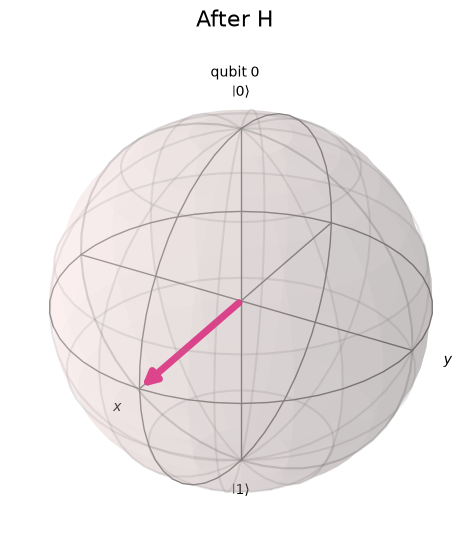

After X: chance of 0 = 0%, chance of 1 = 100%


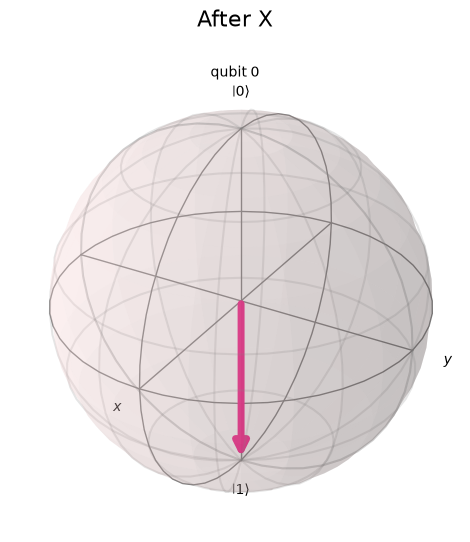

In [3]:
for circuit in (h_circuit, x_circuit):
    state = Statevector(circuit)
    probabilities = state.probabilities()
    print(f"After {circuit.name}: chance of 0 = {probabilities[0]:.0%}, chance of 1 = {probabilities[1]:.0%}")
    display(plot_bloch_multivector(state, title=f"After {circuit.name}"))
    plt.close("all")

## Step 4: Measure on the simulator

Measuring forces the qubit to answer with a plain 0 or 1. One measurement is called a **shot**. To see the chances, we prepare the qubit and measure it **1024 times**.

We fix the simulator's random seed so this notebook prints the same numbers every time it runs.

In [4]:
simulator = AerSimulator(seed_simulator=42)

ideal_counts = {}
for circuit in (h_circuit, x_circuit):
    measured = circuit.copy()
    measured.measure_all()
    result = simulator.run(transpile(measured, simulator), shots=SHOTS).result()
    ideal_counts[circuit.name] = result.get_counts()
    print(circuit.name, ideal_counts[circuit.name])

H {'0': 526, '1': 498}
X {'1': 1024}


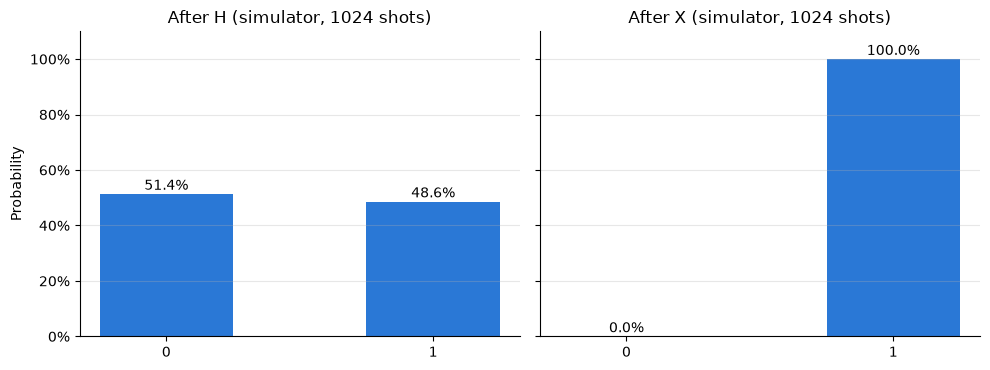

In [5]:
def label_bars(ax, bars, counts_list):
    for bar, count in zip(bars, counts_list):
        ax.annotate(f"{count / SHOTS:.1%}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, name in zip(axes, ("H", "X")):
    counts = [ideal_counts[name].get(outcome, 0) for outcome in ("0", "1")]
    bars = ax.bar(["0", "1"], [c / SHOTS for c in counts], color=BLUE, width=0.5)
    label_bars(ax, bars, counts)
    ax.set_title(f"After {name} (simulator, {SHOTS} shots)")
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Probability")
plt.tight_layout()
plt.show()

As expected, **H** gives close to 50/50. It's not exactly 50/50, because 1024 random shots never split perfectly evenly. **X** gives 1 on every single shot, because a perfect computer makes no mistakes.

## Step 5: Load the real hardware results

We ran the same two circuits from the app on **`ibm_fez`**, a real IBM quantum computer, with 1024 shots each. The results are published in `docs/hardware_results.md`. Here we read the tables in that file, so the numbers below are exactly the published ones.

In [6]:
report = Path("docs/hardware_results.md").read_text()

# Rows of the "Runs" table, e.g. | \|0⟩ → H | `ibm_fez` | `job id` | submitted | finished |
runs = {
    gate: {"backend": backend, "job_id": job_id, "submitted": submitted}
    for gate, backend, job_id, submitted in re.findall(
        r"^\| \\\|0⟩ → (\w+) \| `(\w+)` \| `(\w+)` \| ([^|]+?) \|", report, re.M
    )
}
# Rows of the "Counts" table, e.g. | H | 0 | 526 (51.4%) | 502 (49.0%) |
real_counts, published_ideal = {}, {}
for gate, outcome, ideal, real in re.findall(
    r"^\| (\w+) \| ([01]) \| (\d+) \([\d.]+%\) \| (\d+) \([\d.]+%\) \|", report, re.M
):
    real_counts.setdefault(gate, {})[outcome] = int(real)
    published_ideal.setdefault(gate, {})[outcome] = int(ideal)

for gate in ("H", "X"):
    run = runs[gate]
    print(f"{gate}: backend {run['backend']}, job {run['job_id']}, submitted {run['submitted']} UTC")
    print(f"   real counts: {real_counts[gate]}  (total {sum(real_counts[gate].values())} shots)")

H: backend ibm_fez, job dbpp2doou4as73cu1dtg, submitted 2026-11-10 20:45:45 UTC
   real counts: {'0': 502, '1': 522}  (total 1024 shots)
X: backend ibm_fez, job dbpp4b0ou4as73cu1g30, submitted 2026-11-10 21:52:44 UTC
   real counts: {'0': 40, '1': 984}  (total 1024 shots)


## Step 6: Compare ideal vs real

Blue bars are the perfect simulator from Step 4, and orange bars are the real quantum computer.

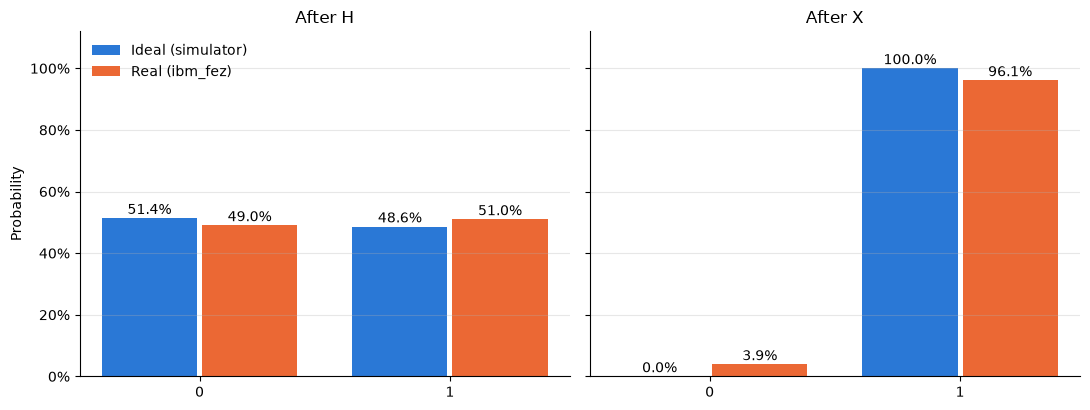

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, ("H", "X")):
    ideal = [ideal_counts[name].get(o, 0) for o in ("0", "1")]
    real = [real_counts[name].get(o, 0) for o in ("0", "1")]
    positions = range(2)
    width = 0.38
    ideal_bars = ax.bar([p - width / 2 - 0.01 for p in positions], [c / SHOTS for c in ideal], width, color=BLUE, label="Ideal (simulator)")
    real_bars = ax.bar([p + width / 2 + 0.01 for p in positions], [c / SHOTS for c in real], width, color=ORANGE, label=f"Real ({runs[name]['backend']})")
    label_bars(ax, ideal_bars, ideal)
    label_bars(ax, real_bars, real)
    ax.set_xticks(list(positions), ["0", "1"])
    ax.set_title(f"After {name}")
    ax.set_ylim(0, 1.12)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Probability")
axes[0].legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## Step 7: What the difference tells us

Even a perfect computer's results wobble a little, because 1024 random shots never land exactly on the true odds. For a 50/50 result, that wobble is about ±1.6 percentage points (one standard deviation). The cell below checks each real result against that yardstick.

In [8]:
import math

h_real = real_counts["H"]["0"] / SHOTS
wobble = math.sqrt(0.5 * 0.5 / SHOTS)
print(f"H: real chance of 0 = {h_real:.1%}. Distance from 50% = {abs(h_real - 0.5):.1%}, "
      f"which is {abs(h_real - 0.5) / wobble:.1f}x the normal shot-to-shot wobble ({wobble:.1%}).")

x_errors = real_counts["X"].get("0", 0)
print(f"X: the qubit should read 1 every time, but the real computer read 0 on "
      f"{x_errors} of {SHOTS} shots ({x_errors / SHOTS:.1%}).")

H: real chance of 0 = 49.0%. Distance from 50% = 1.0%, which is 0.6x the normal shot-to-shot wobble (1.6%).
X: the qubit should read 1 every time, but the real computer read 0 on 40 of 1024 shots (3.9%).


- **H:** the real result sits within the normal shot-to-shot wobble, so this run can't tell hardware noise apart from ordinary chance.
- **X:** here the hardware's mistakes are easy to see. A perfect computer reads 1 every time, but `ibm_fez` read 0 on about 4% of shots.

**Why do real quantum computers make mistakes?** Qubits are extremely sensitive. A tiny bit of heat or electrical noise can disturb them. Over time a qubit loses its quantum state, which is called **decoherence**. In particular, a qubit in state 1 can relax back down to 0. The final readout can also mistake a 1 for a 0. That's why a real computer's X result isn't a perfect 100%.

## Summary

- **Simulator:** a perfect computer, so its results match the theory, apart from the random spread of 1024 shots.
- **Real quantum computer:** close to the ideal results, but a few percent of shots are wrong because of noise.
- **The app:** to explore further, open Qubit Visualizer, try other gates, and switch the knowledge level to see the math behind each step.